# Mix Revision Analyzer

Can we idenfity when a mix revision changed the frequency balance and which band it affected?

## Load and validate the WAV Files

The original mix is our reference. The revision contains a bell cut near 300 Hz from about 10 to 20 seconds. We check that both exports have the same sample rate, sample count, and channel count so we can compare them on the same time grid. 

In [1]:
# Load and validate the WAV files

from scipy.io import wavfile

In [2]:
# Read both exports at their original sample rates

sr_original, original = wavfile.read("A original.wav")
sr_revision, revision = wavfile.read("B Revision.wav")

C:\Users\abeth\AppData\Local\Temp\ipykernel_10852\53851494.py:3: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr_original, original = wavfile.read("A original.wav")
C:\Users\abeth\AppData\Local\Temp\ipykernel_10852\53851494.py:4: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr_revision, revision = wavfile.read("B Revision.wav")


**The red output is a warning. SciPy skipped a section it didn't recognize and still loaded the samples.**

In [3]:
# Verify that both WAV files have matching audio properties

assert sr_original == sr_revision, "Sample rates must match."
assert original.shape == revision.shape, "Sample counts and channel counts must match."

# Display the duration, sample rate, and channel count. 

print(f'Duration: {len(original)/sr_original:.2f} s')
print(f'Sample rate: {sr_original:,} Hz')
print(f'Channels: {original.shape[1]}')

Duration: 30.00 s
Sample rate: 44,100 Hz
Channels: 2


## 2. Measure frequencies over time 

We use a short-time Fourier transform to take overlapping frequency snapshots of both recordings. This lets us track when the frequency balance changes throughout the clip. 

In [4]:
import librosa
import numpy as np
import importlib

In [5]:
# Convert the 32-bit PCM samples to floats using the same scale for both files
# Transpose the arrays so librosa receives

pcm_scale = 2 ** 31
original_audio = original.T.astype(np.float32) / pcm_scale
revision_audio = revision.T.astype(np.float32) / pcm_scale

# Use the same window size and spacing for both recordings

window_length = 4096
hop_length = 1024

# Compute one spectrum per window for each channel
original_stft = librosa.stft(
    original_audio, n_fft = window_length, hop_length = hop_length, center = False)

revision_stft = librosa.stft(revision_audio, n_fft = window_length,
                             hop_length = hop_length, center = False)

# Check the dimension before comparing the two results

print("Original STFT shape:", original_stft.shape)
print("Revision STFT shape:", revision_stft.shape)
      

Original STFT shape: (2, 2049, 1288)
Revision STFT shape: (2, 2049, 1288)


## Select the 200 - 500 Hz band

We map the STFT bins to frequencies in Hz and keep the bins within our target band. This band contains the center frequency of the EQ cut. 

In [6]:
# Label each STFT bin in Hz in both recordings.

frequencies_hz = np.fft.rfftfreq(window_length, d=1 / sr_original)

# Mark each bin True if its frequency falls within our target band

low_mid_mask = (frequencies_hz >= 200) & (frequencies_hz < 500)
low_mid_frequencies = frequencies_hz[low_mid_mask]

# Keep both channels and every time window, selecting only the target bins

original_low_mid = original_stft[:, low_mid_mask, :]
revision_low_mid = revision_stft[:, low_mid_mask, :]

# Check which frequencies were kept and how the array shape changed 

print("Number of bins:", low_mid_frequencies.size)
print(f'First and last bin: {low_mid_frequencies[0]:.2f}-{low_mid_frequencies[-1]:.2f} Hz')
print("Selected STFT shape:", original_low_mid.shape)

Number of bins: 28
First and last bin: 204.57-495.26 Hz
Selected STFT shape: (2, 28, 1288)


# Measure and plot low-mid band power

For each time window, we sum the power across the selected frequency bins for both stereo channels. This gives us one low-mid power value per window for each recording. As a quick check, we compare the values around 15 seconds, where we expect the revision to have lower mid-range power than the original. Then we plot both recordings from 14 to 16 seconds to see whether the lower-frequency (200-500 Hz) power persists across neighboring windows. The dashed line marks the window we're checking near 15 seconds.  

In [7]:
# Square the magnitude of each frequency bin, 
# then sum across both channels(axis 0) and all select frequency bins (axis 1)

original_band_power = np.sum(np.abs(original_low_mid) ** 2, axis = (0,1))
revision_band_power = np.sum(np.abs(revision_low_mid) ** 2, axis = (0,1))

# Compare both versions near 15 seconds, inside the EQ cut

middle_frame = len(original_band_power) // 2
print("Original shape:", original_band_power.shape)
print('Revision shape:', revision_band_power.shape)
print(f'Original near 15s: {original_band_power[middle_frame]:.2f}')
print(f'Revision near 15s: {revision_band_power[middle_frame]:.2f}')

Original shape: (1288,)
Revision shape: (1288,)
Original near 15s: 52924.91
Revision near 15s: 17432.30


### Inspect the low-mid band near 15 seconds

We plot both recordings from 14 to 16 seconds to see whether the lower 200 - 500 hz power persists across neighboring windows. The dashed line marks the windows we checked near 15 secons. The vertical axis shows raw band power in arbitrary units. 

<function matplotlib.pyplot.show(close=None, block=None)>

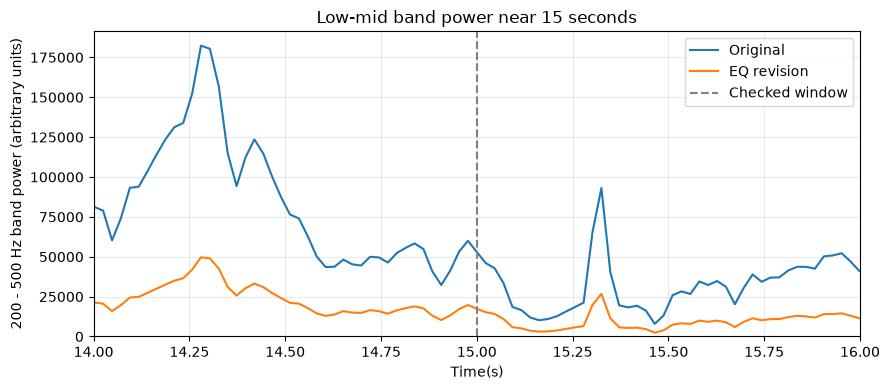

In [8]:
# Plot the original and revised low-mid band power around 15 seconds. 

import matplotlib.pyplot as plt

# Convert each window's center from a sample index to seconds

frame_indices = np.arange(original_band_power.size)
frame_times_s = (frame_indices * hop_length + window_length / 2) / sr_original

# Keep the windows whose centers fall between 14 and 16 seconds 

near_15s = (frame_times_s >= 14) & (frame_times_s <= 16)

# Plot both versions on the same axes

fig, ax = plt.subplots(figsize =(9,4))
ax.plot(frame_times_s[near_15s], original_band_power[near_15s], label = 'Original')
ax.plot(frame_times_s[near_15s], revision_band_power[near_15s], label = "EQ revision")
ax.axvline(frame_times_s[middle_frame], color = 'gray', linestyle = '--',
           label = "Checked window")

ax.set(title = "Low-mid band power near 15 seconds", xlabel = "Time(s)",
       ylabel = '200 - 500 Hz band power (arbitrary units)', 
       xlim = (14, 16),)

ax.set_ylim(bottom = 0)
ax.grid(alpha = 0.25)
ax.legend()
fig.tight_layout()
plt.show

## Convert the band-power change to decibels

For each time windows, we divide the revision's 200 - 500 hz band power by the original's band power and conver the ratio to decibels. We check three points: before, during, and after the EQ cut.

In [9]:
# Mark windows where bot files have positive power so the dB ratio is finite

valid_power = (original_band_power > 0 ) & (revision_band_power > 0)
band_change_db = np.full(original_band_power.shape, np.nan)

# Divide revision power by original power and convert the ratio to dB

power_ratio = revision_band_power[valid_power] / original_band_power[valid_power]
band_change_db[valid_power] = 10 * np.log10(power_ratio)

# Find the window closest to each checkpoint and print its change

for target_time in (5, 15, 25):

    frame = np.argmin(np.abs(frame_times_s - target_time))
    print(f"Near {target_time: 2d} s{band_change_db[frame]:+.2f} dB")

Near  5 s+0.00 dB
Near  15 s-4.82 dB
Near  25 s+0.00 dB


## Visualize the low-mid change across the recording

We plot the revision-to-original band-power difference over time. A value of 0 dB means equal band power, while negative values mean the revision has less power in the 200 - 500 Hz band. 

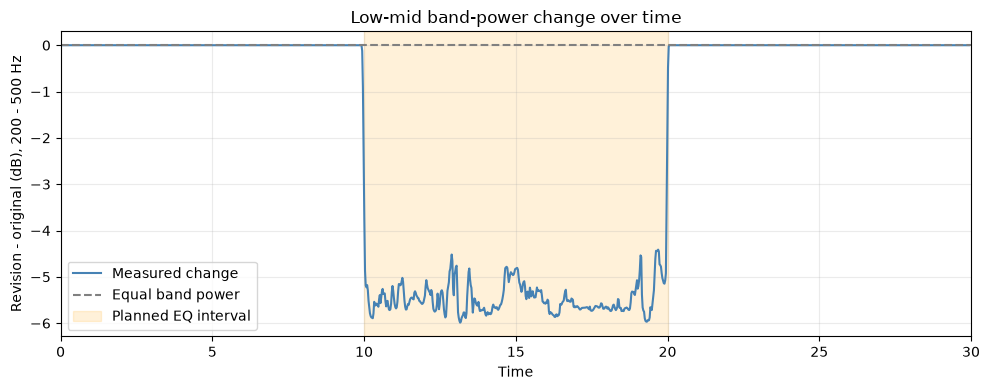

In [10]:
# Plot one measured dB difference for each analysis windows

fig, ax = plt.subplots(figsize = (10, 4))
ax.plot(frame_times_s, band_change_db, label = 'Measured change', color = 'steelblue',)

# Mark equal band power and the interval where we applied the EQ.

ax.axhline(0, color = 'gray', linestyle = '--', label = "Equal band power")
ax.axvspan(10,20, color = 'orange', alpha = 0.15, label = 'Planned EQ interval')

# Label and display the full duration of the recording.

ax.set( title = 'Low-mid band-power change over time', xlabel = 'Time',
        ylabel = 'Revision - original (dB), 200 - 500 Hz',
        xlim = (0, len(original) / sr_original), )

ax.grid(alpha = 0.25)
ax.legend()
fig.tight_layout()
plt.show()

**The shaded region marks the planned EQ interval from 10 to 20 seconds so we can compare the measured change with our known edit.**

### Findings 

The measured 200 - 500 Hz band-power difference stays near 0 dB outside the planned edit interval and drops to approximately -4.5 to -6 dB during the interval from 10 to 20 seconds.

This matches the timing and direction of the known EQ cut. The variation within the edited interval reflects changes in how the music's energy is distribute across the bell filter's response. 

## Compare changes across frequency bands

Now, we calculate the revision-to-original power difference for five frequency bands, preserving one measurement per time window. 

As a first comparison, we report the median change from 12 to 28 seconds. This interval sits inside the EQ cut and avoids its transitions. 

In [11]:
# Define each band's label and its lower and upper frequency boundaries

frequency_bands = {'20 - 200 Hz': (20, 200), '200 - 500 Hz': (200, 500), 
                   '500 - 2000Hz': (500, 2000), '2000 - 5000 Hz': (2000, 5000),
                   '5000 - 10000 Hz': (5000, 10000),}

# Calculate power for all STFT bins in both recordings 

original_power = np.abs(original_stft) ** 2
revision_power = np.abs(revision_stft) ** 2

# Store each band's full time series 

band_changes_db = {}
inside_cut = (frame_times_s >= 12) & (frame_times_s < 18)

# Repeat the same calculation for every frequency band

for band_name, (low_hz, high_hz) in frequency_bands.items():
    band_mask = (frequencies_hz >= low_hz) & (frequencies_hz < high_hz)

    original_power_in_band = original_power[:, band_mask, :].sum(axis = (0, 1))
    revision_power_in_band = revision_power[:, band_mask, :].sum(axis = (0,1))

    valid = (original_power_in_band > 0) & (revision_power_in_band > 0)
    change_db = np.full(original_power_in_band.shape, np.nan)
    change_db[valid] = 10 * np.log10(revision_power_in_band[valid] 
                                     / original_power_in_band[valid])

    band_changes_db[band_name] = change_db
    print(f'{band_name}: {np.nanmedian(change_db[inside_cut]):+.2f} dB')

20 - 200 Hz: -0.80 dB
200 - 500 Hz: -5.57 dB
500 - 2000Hz: -1.61 dB
2000 - 5000 Hz: -0.15 dB
5000 - 10000 Hz: -0.03 dB


## Visualize changes across frequency bands

We plot each band's power difference across the full recording. This shows whether the changes occur during the known EQ interval and which frequency band has the strongest reduction. 

The previously reported values summarize 12- 18 seconds. These curves show the individual measurement throughout the clip. 

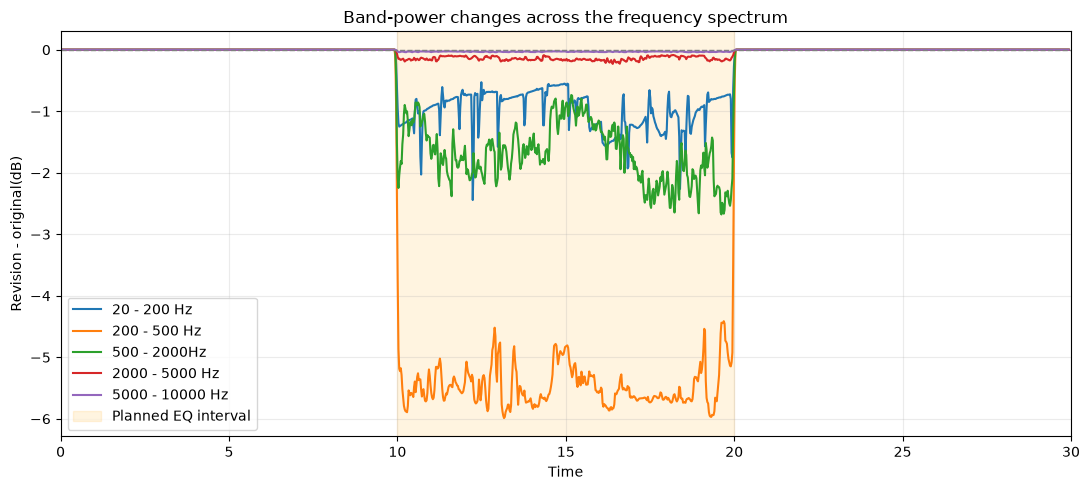

In [12]:
# Plot all five frequency bands across the full recording.
plt = importlib.reload(plt)
fig, ax = plt.subplots(figsize = (11, 5))

# Draw one line per band 
for band_name, change_db in band_changes_db.items():
    ax.plot(frame_times_s, change_db, label = band_name)

# Mark equal power and the planned EQ interval.
ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
ax.axvspan(10, 20, color = 'orange', alpha = 0.12, label = "Planned EQ interval")

# Label the plot and display the full recording duration 

ax.set(title = "Band-power changes across the frequency spectrum",
       xlabel = "Time",
       ylabel = 'Revision - original(dB)',
       xlim = (0, len(original) / sr_original),)

ax.grid(alpha = 0.25)
ax.legend()
fig.tight_layout()
plt.show()



## Create a gain-only control

We reduce the original recording's level by 3 dB throughout the clip. This applies the same gain change to every frequency.

We then analyze it using the same STFT settings as the original and the EQ revision. We expect approximately -3 dB in every frequency band where there is enough signal to measure.

(This step will be beneficial for the next version of this analyzer.)

In [13]:
# Create a version of the original recording with a uniform -3b gain change

gain_db = -3.0
gain_factor = 10 ** (gain_db / 20)

gain_only_audio = original_audio * gain_factor

# Analyze the control using the same window size and spacing

gain_only_stft = librosa.stft( gain_only_audio, n_fft = window_length, hop_length = hop_length,
                               center = False,)

# Calculate power for the later frequency-band comparison

gain_only_power = np.abs(gain_only_stft) ** 2

print(f'Amplitude multiplier: {gain_factor:.4f}')
print('Gain-only STFT shape:', gain_only_stft.shape)

Amplitude multiplier: 0.7079
Gain-only STFT shape: (2, 2049, 1288)


## Validate the gain-only control 

We measure the control's power change relative to the original in each frequency band. Because we applied a uniform -3 dB gain change, we expect approximately -3 dB in every throughout the recording. 

We report the median change and the largest deviation from the expected value across valid time windows. 

In [14]:
# Check whether the gain-only control produces - 3dB in every band

gain_band_changes_db = {}

for band_name, (low_hz, high_hz) in frequency_bands.items():
    band_mask = (frequencies_hz >= low_hz) &(frequencies_hz < high_hz)
    reference_power = original_power[:, band_mask, :].sum(axis = (0, 1))
    control_power = gain_only_power[:, band_mask, :].sum(axis = (0,1))

    valid = (reference_power > 0) & (control_power > 0)
    change_db = np.full(reference_power.shape, np.nan)
    change_db[valid] = 10 * np.log10(control_power[valid] / reference_power[valid])

    gain_band_changes_db[band_name] = change_db
    max_error_db = np.nanmax(np.abs(change_db - gain_db))

    print(f'{band_name}: median {np.nanmedian(change_db):+.2f} dB,'
        f'maximum eror {max_error_db:.6f} dB')

20 - 200 Hz: median -3.00 dB,maximum eror 0.000003 dB
200 - 500 Hz: median -3.00 dB,maximum eror 0.000003 dB
500 - 2000Hz: median -3.00 dB,maximum eror 0.000005 dB
2000 - 5000 Hz: median -3.00 dB,maximum eror 0.000008 dB
5000 - 10000 Hz: median -3.00 dB,maximum eror 0.000011 dB


### Findings

All five frequency bands sho a median change of -3 dB. The largest deviation from the applied gain across valid time windows is 0.000011 dB, consistent with numerical rounding. 

The control produces the expected uniform change across bands. The EQ revision produces unequal changes, with the strongest reduction in the 200 - 500 Hz band. 

## Compare frequency balance independently of overall level 

Here we calculate each band's change relative to the total analyzed power 20 hz and 10 kHz. Subtracting the total-power change from each band's power change gives the change in that band's share. 

The gain-only control should produce values near zero. The EQ revision should retain a reduction in the low-mid band's share. 

These measurements describe relative balance. A band's share can increase when another band is cut, even if its own absolute power decreases. 

In [15]:
# Calculate the reference total across the range covered by our five bands. 

analyzed_mask = (frequencies_hz >= 20) & (frequencies_hz < 10000)
original_total_power = original_power[:, analyzed_mask, :].sum(axis = (0, 1))

total_changes_db = {}

for version_name, power in [
    ("EQ revision", revision_power),
    ("Gain control", gain_only_power),]:
    comparison_total_power = power[:, analyzed_mask, :].sum(axis =(0,1))
    valid = (original_total_power > 0) & (comparison_total_power > 0)
    total_change_db = np.full(original_total_power.shape, np.nan)
    total_change_db[valid] = 10 * np.log10(comparison_total_power[valid] 
                                           / original_total_power[valid])
    total_changes_db[version_name] = total_change_db


eq_balance_changes_db = {}
gain_balance_changes_db = {}

for band_name in frequency_bands:
    eq_balance_changes_db[band_name] =(
        band_changes_db[band_name] - total_changes_db['EQ revision'])
    gain_balance_changes_db[band_name] = ( gain_band_changes_db[band_name] 
                                           - total_changes_db['Gain control'])

    eq_median = np.nanmedian(eq_balance_changes_db[band_name][inside_cut])
    control_error = np.nanmax(np.abs(gain_balance_changes_db[band_name]))

    print(f'{band_name}: EQ median {eq_median:+.2f} dB,'
          f'control max change {control_error:+6f} dB')
    
        

20 - 200 Hz: EQ median +1.42 dB,control max change +0.000014 dB
200 - 500 Hz: EQ median -2.96 dB,control max change +0.000013 dB
500 - 2000Hz: EQ median +0.93 dB,control max change +0.000015 dB
2000 - 5000 Hz: EQ median +2.19 dB,control max change +0.000015 dB
5000 - 10000 Hz: EQ median +2.32 dB,control max change +0.000015 dB


## Visualize changes in frequency balance 

We compare the EQ revision and gain-only control after accounting for changes in total analyzed power. 

Both panels use the same time and dB scales. The EQ revision should show changes in band shares during the edit interval. The gain-only control should remain near zero throughout the recording. 

Positive values indicate an increased share of analyzed power. 
Negative values indicate a decreased share. 

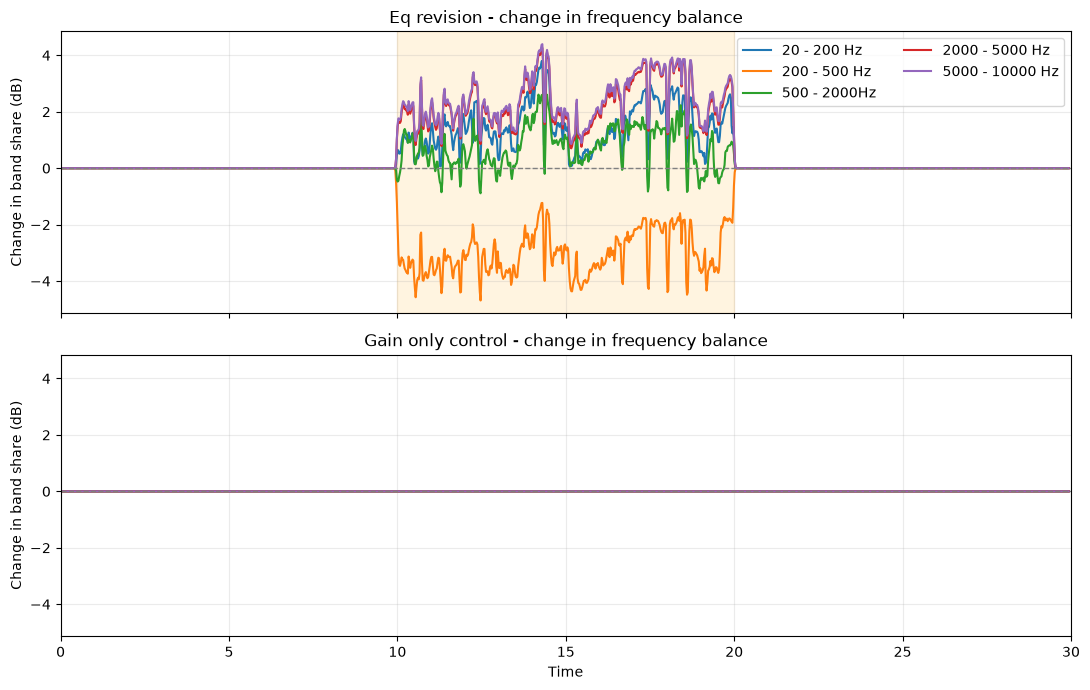

In [16]:
# Create two panels with matching time and dB scales.

fig, (ax_eq, ax_gain) = plt.subplots(2, 1, figsize = (11, 7), sharex = True, sharey = True)

# Plot each band in both panels.

for band_name in frequency_bands:
    ax_eq.plot(frame_times_s, eq_balance_changes_db[band_name], label = band_name)
    ax_gain.plot(frame_times_s, gain_balance_changes_db[band_name], label = band_name)

ax_eq.axvspan(10, 20, color = 'orange', alpha = 0.12)
ax_eq.set_title("Eq revision - change in frequency balance")
ax_gain.set_title("Gain only control - change in frequency balance")

for ax in (ax_eq, ax_gain):
    ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
    ax.set_ylabel("Change in band share (dB)")
    ax.grid(alpha = 0.25)

ax_eq.legend(ncol = 2)
ax_gain.set_xlabel("Time")
ax_gain.set_xlim(0, len(original) / sr_original)

fig.tight_layout()
plt.show()
        
    

### Insights

The EQ revision shows a reduced share of power in the 200 - 500 Hz band during approximately 10 - 20 seconds. Other bands occupy a larger share after the low-mid cut. 

The gain-only control stays near zero across all bands after normalization. This shows that the band-share comparison removes the uniform level change in this controlled test. 

Together, these experiments show that the analysis captures the timing and frequency region of the known edit while preserving frequency balance under uniform gain changes.

## Validate the controlled experiments

We check that all balance measurements are finite, the gain-only control stays near zero, and the strongest raw reduction occurs in 200 - 500 hz.

We also require the target band's median share change over 12 - 18 seconds to fall below -1 dB. Outside the planned 10 - 20 second edit, balance changes must stay near zero. 

These thresholds define acceptance checks for our known experiment.

In [17]:
# Validate the results of our controlled EQ and gain experiements

numerical_tolerance_db = 0.001
minimum_cut_db = 1.0 
transition_margin_s = 0.2

eq_matrix  = np.stack(list(eq_balance_changes_db.values()))
gain_matrix = np.stack(list(gain_balance_changes_db.values()))

assert np.isfinite(eq_matrix).all(), "Invalid EQ balance measurements."
assert np.isfinite(gain_matrix).all(), 'Invalid gain-control measurements.'

control_max_db = np.max(np.abs(gain_matrix))
assert control_max_db < numerical_tolerance_db, "Gain control failed"

# Find the target band by its boundaries

target_band = next(
    name for name, limits in frequency_bands.items() if limits == (200, 500))


raw_medians = {name: np.median(values[inside_cut])
               for name, values in band_changes_db.items()}

strongest_cut_band = min(raw_medians, key = raw_medians.get)
assert strongest_cut_band == target_band, "Strongest cut is outside the target band."

target_median_db = np.median(eq_balance_changes_db[target_band][inside_cut])
assert target_median_db < -minimum_cut_db, 'Expected low-mid reduction is missing.'

# Check that the EQ balance stays near zero 

outside_cut = ((frame_times_s < 10 - transition_margin_s) | 
               (frame_times_s > 20 + transition_margin_s))

outside_max_db = np.max(np.abs(eq_matrix[:, outside_cut]))
assert outside_max_db < numerical_tolerance_db, 'Changes found outside the cut'

print('All controlled experiment checks passed.')
print(f'Control maximum balance change: {control_max_db:.6f} dB')
print(f"Strongest raw reduction: {strongest_cut_band}")
print(f"Target median balance change: {target_median_db:.2f} dB")
print(f'Maximum change outside edit: {outside_max_db:.6f} dB')

All controlled experiment checks passed.
Control maximum balance change: 0.000015 dB
Strongest raw reduction: 200 - 500 Hz
Target median balance change: -2.96 dB
Maximum change outside edit: 0.000000 dB


# Overall Findings and Limitations

### Findings

In this analysis, we compared two aligned, 30-second stereo exports of the same recording. The revision contained a bell cut centered near 300 Hz, with approximately -6.08 using FabFilter EQ. 

The strongest median raw power reduction during 12 - 18 seconds occurred in the 200 - 500 Hz band, at approximately -5.57 dB. 

After expressing each band's power relative to the total analyzed power between 20 Hz and 10 kHz, the low-mid band's median share change was approximately -2.96 dB. The plots showed this reduction during the known edit interval. 

A separate control applied a uniform -3 dB gain change to the original. Its raw measurements showed approximately - 3 dB in every band. Its largest absolute change in balance was approximately 0.000015 dB. 

All controlled-experiment checks passed. These results support using band-power and band-share comparisons to examine the timing and spectral location of this known mix revision while accounting for uniform gain. 

### Limitations

- Validation covers one recording, one automated bell cut, and one uniform gain reduction. Additional recordings and processing types are needed to evaluate broader reliability.

- Comparisons require aligned versions of the same audio. Automatic alignment is a future extension.

- Five broad frequency bands identify the affected region. Recovering the exact EQ center, gain, and Q would require additional analysis.

- Silence and very weak signals require explicit handling for broader use. Current validation expects finite measurements throughout this clip.

- Acceptance thresholds were chosen for this controlled experiment. Reliability on new mixes requires further validation. 
